In [1]:
from os import path

import mne_bids
import numpy as np
from mne.parallel import parallel_func

import mvEEG.mvEEG as mvEEG

from tqdm.notebook import tqdm
import argparse

import pandas as pd
import pingouin as pg
from collections import defaultdict

from scipy.stats import scoreatpercentile
import seaborn as sns
import matplotlib.pyplot as plt

from mne.stats import permutation_cluster_1samp_test

from glob import glob

import json

import pymc as pm
import arviz as az

%load_ext autoreload
%autoreload 2

In [2]:
RUN_DESCRIPTION = "A2PvsA4P"
np.random.seed(42)
OVERWRITE = False

In [3]:
import json

with open("rejected_subs.json", "r") as f:
    rejected_subs = json.load(f)
rejected_subs

['006', '008', '017', '018', '020', '023', '024', '016']

In [4]:
training_labels = RUN_DESCRIPTION.split("vs")
if "M" in training_labels[0]:
    task = "WM"
    main_conds = ["M2P", "M4P", "M6P", "M8P", "M2N", "M4N", "M6N", "M8N"]
    alt_conds = ["A2P", "A4P", "A6P", "A8P", "A2N", "A4N", "A6N", "A8N"]
else:
    task = "ATT"
    main_conds = ["A2P", "A4P", "A6P", "A8P", "A2N", "A4N", "A6N", "A8N"]
    alt_conds = ["M2P", "M4P", "M6P", "M8P", "M2N", "M4N", "M6N", "M8N"]

code_dict = {
    "A2N": 12,
    "A4N": 14,
    "A6N": 16,
    "A8N": 18,
    "A2P": 22,
    "A4P": 24,
    "A6P": 26,
    "A8P": 28,
    "M2N": 32,
    "M4N": 34,
    "M6N": 36,
    "M8N": 38,
    "M2P": 42,
    "M4P": 44,
    "M6P": 46,
    "M8P": 48,
}
conditions = list(code_dict.keys())

train_codes = [code_dict[cond] for cond in training_labels]


ROOT = "../data/derivatives"
DATA_DIR = ROOT
EXPERIMENT_NAME = "banyan"
dropped_chans = {"eeg": ["TP9", "Fp1", "Fp2"], "eog": "ALL", "eyegaze": [], "pupil": [], "misc": "ALL"}
# EOG and EYE channels will be analyzed separately, to see if they drive decoding results
# EOG_CHANS = ["HEOG", "VEOG"]
EYE_CHANS = ["xpos_left", "xpos_right", "ypos_left", "ypos_right", "pupil_left", "pupil_right"]

SUB_IGNORE_CHANS = {}
bad_epochs = (
    {  # epochs which didn't align with eye tracking for one reason or another, and were excluded during preprocessing
        "010": [0, 1, 2, 3],
        "011": [971],
        "017": [1588],
        "031": [1571],
    }
)
old_beh_format = ["001", "002"]
isub_makeup_error_trials = {"001": 2}  # after exclusion, the last n trials which need dropped due to errors in saving

wrangl = mvEEG.Wrangler(
    data_dir=DATA_DIR,
    experiment_name=EXPERIMENT_NAME,
    dropped_chans=dropped_chans,
    t_win=50,
    t_step=25,
    trim_timepoints=[-350, 1000],
    trial_bin_size=15,
    n_folds=2,  # NOTE: _not_ using wrangler n_folds here
)

delay_window = (wrangl.t > 300) & (
    wrangl.t < 900
)  # time window to average distances over, only includes when probes could appear

In [5]:
interp = mvEEG.Interpreter(
    data_dir=ROOT,
    experiment_name=EXPERIMENT_NAME,
    descriptions=[RUN_DESCRIPTION],
    labels=[0, 1],
    trial_phases={"Stim": (0, 200)},
    key_set=["predsPerTrial", "predsPerTrialEYES", "times", "classifierConditions"]
)

preds_perTrial, preds_EYES_perTrial, times, conds = interp.dataset.get_data(
    None, keys=["predsPerTrial", "predsPerTrialEYES", "times", "classifierConditions"]
)

del interp  # free up memory, since we don't need it anymore

/Users/henryjones/Documents/research/banyan/Experiment 1/analyses/mvEEG/mvEEG/dataloader.py:101: UserWarning: Data files have inconsistent shapes: [[1000 1131   55]
 [1000 1184   55]
 [1000 1189   55]
 [1000 1253   55]
 [1000 1260   55]
 [1000 1286   55]
 [1000 1291   55]
 [1000 1313   55]
 [1000 1315   55]
 [1000 1319   55]
 [1000 1323   55]
 [1000 1334   55]
 [1000 1341   55]
 [1000 1358   55]
 [1000 1359   55]
 [1000 1360   55]
 [1000 1362   55]
 [1000 1367   55]
 [1000 1382   55]
 [1000 1388   55]
 [1000 1394   55]
 [1000 1401   55]
 [1000 1402   55]
 [1000 1409   55]
 [1000 1431   55]
 [1000 1436   55]]
  warnings.warn(f"Data files have inconsistent shapes: {shape}")
/Users/henryjones/Documents/research/banyan/Experiment 1/analyses/mvEEG/mvEEG/dataloader.py:101: UserWarning: Data files have inconsistent shapes: [[1131]
 [1184]
 [1189]
 [1253]
 [1260]
 [1286]
 [1291]
 [1313]
 [1315]
 [1319]
 [1323]
 [1334]
 [1341]
 [1358]
 [1359]
 [1360]
 [1362]
 [1367]
 [1382]
 [1388]
 [1394]
 [14

In [6]:
# mean across iterations
preds_perTrial_meaned = [p.mean(0) for p in preds_perTrial]
del preds_perTrial  # free up memory, since we don't need it anymore

In [7]:
preds_EYES_perTrial_meaned = [p.mean(0) for p in preds_EYES_perTrial]
del preds_EYES_perTrial  # free up memory, since we don't need it anymore

In [8]:
# rename for simplicity
preds_perTrial = preds_perTrial_meaned
preds_EYES_perTrial = preds_EYES_perTrial_meaned

# For each subject, build up their (roughly) delay period classification scores from EEG and Eyes

In [9]:
def rescale_conds(conds):
    # rescale conditions to be between 0 and 1, for better interpretability in modeling
    return (conds - conds.min()) / (conds.max() - conds.min())

In [10]:
eeg_window = delay_window
eye_window = (times > 600) & (times < 900)
pupil_window = (times > 600) & (times < 900)


preds_df = pd.DataFrame()
for isub in range(len(preds_perTrial)):
    sub_preds = preds_perTrial[isub]
    sub_preds_EYES = preds_EYES_perTrial[isub]
    sub_conds = conds[isub]
    cond_mask = np.isin(sub_conds, train_codes)
    # subset to training conditions only, since we're only interested in MI between conditions making up the contrast, for now,
    # average across iterations, and then across the delay period
    sub_preds = sub_preds[cond_mask][:, eeg_window].mean(1)
    sub_preds_EYES = sub_preds_EYES[cond_mask][:, eye_window].mean(1)
    sub_conds = sub_conds[cond_mask]

    sub_df = pd.DataFrame({"EEG": sub_preds, "EYE": sub_preds_EYES, "cond": rescale_conds(sub_conds)})
    sub_df["sub"] = isub
    preds_df = pd.concat([preds_df, sub_df], ignore_index=True)

preds_df["cond"] -= 0.5  # rescale conditions to be between -0.5 and 0.5, for better interpretability in modeling

# Bayesian Modeling

In [11]:
subjects = preds_df["sub"].unique()
preds_df

,EEG,EYE,cond,sub
0,0.876733,0.534216,-0.5,0
1,-0.454969,0.284124,0.5,0
2,0.235477,-0.885256,0.5,0
3,0.176228,-0.194518,0.5,0
4,-0.315060,-0.662364,0.5,0
...,...,...,...,...
4353,-0.373549,-0.668241,-0.5,25
4354,-0.300726,0.136215,0.5,25
4355,-1.267005,0.374988,0.5,25
4356,0.566852,0.461927,0.5,25


In [12]:
def build_model(preds_df, eye_col="EYE"):
    with pm.Model() as model:
        # multivele model predicting EEG from EYE and condition, with random intercepts for subjects

        # hyperpriors for group-level parameters
        mu_intercept = pm.Normal("mu_intercept", mu=0, sigma=1)
        sigma_intercept = pm.HalfNormal("sigma_intercept", sigma=1)
        mu_eye = pm.Normal("mu_eye", mu=0, sigma=1)
        sigma_eye = pm.HalfNormal("sigma_eye", sigma=1)
        mu_cond = pm.Normal("mu_cond", mu=0, sigma=1)
        sigma_cond = pm.HalfNormal("sigma_cond", sigma=1)

        sub_intercept = pm.Normal("sub_intercept", mu=0, sigma=1, shape=len(subjects))
        sub_eye = pm.Normal("sub_eye", mu=0, sigma=1, shape=len(subjects))
        sub_cond = pm.Normal("sub_cond", mu=0, sigma=1, shape=len(subjects))

        intercepts = pm.Deterministic("intercepts", mu_intercept + sub_intercept * sigma_intercept)
        eye_coeffs = pm.Deterministic("eye_coeffs", mu_eye + sub_eye * sigma_eye)
        cond_coeffs = pm.Deterministic("cond_coeffs", mu_cond + sub_cond * sigma_cond)

        mu = (
            intercepts[preds_df["sub"].values]
            + eye_coeffs[preds_df["sub"].values] * preds_df[eye_col].values
            + cond_coeffs[preds_df["sub"].values] * preds_df["cond"].values
        )
        sigma = pm.HalfNormal("sigma", sigma=1)
        EEG_obs = pm.Normal("EEG_obs", mu=mu, sigma=sigma, observed=preds_df["EEG"].values)

    return model

In [13]:
model = build_model(preds_df, eye_col="EYE")

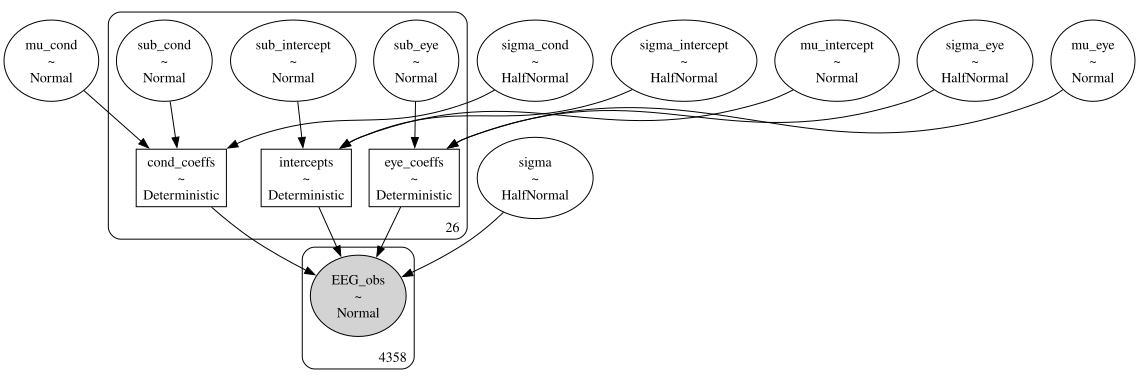

In [14]:
pm.model_to_graphviz(model)

In [15]:
with model:
    trace = pm.sample(
        5000,  # real samples per chain
        tune=4000,  # warmup samples per chain
        chains=4,
        random_seed=0,
        target_accept=0.95,
        return_inferencedata=True,
        idata_kwargs={"log_likelihood": True},
        nuts_sampler="numpyro",
    )
    trace.extend(pm.sample_prior_predictive(20_000))  # add prior predictive samples to the idata for later checks

  0%|          | 0/9000 [00:00<?, ?it/s]

  0%|          | 0/9000 [00:00<?, ?it/s]

  0%|          | 0/9000 [00:00<?, ?it/s]

  0%|          | 0/9000 [00:00<?, ?it/s]

Sampling: [EEG_obs, mu_cond, mu_eye, mu_intercept, sigma, sigma_cond, sigma_eye, sigma_intercept, sub_cond, sub_eye, sub_intercept]


In [16]:
summary_table = az.summary(trace)
summary_table

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
mu_intercept,0.002,0.012,-0.022,0.024,0.000,0.000,40854.0,14783.0,1.0
mu_eye,0.002,0.019,-0.033,0.037,0.000,0.000,32743.0,15392.0,1.0
mu_cond,0.066,0.026,0.016,0.115,0.000,0.000,34141.0,14911.0,1.0
sub_intercept[0],-0.003,0.972,-1.810,1.832,0.005,0.008,44465.0,14723.0,1.0
sub_intercept[1],0.000,0.981,-1.858,1.820,0.005,0.008,45814.0,14435.0,1.0
...,...,...,...,...,...,...,...,...,...
cond_coeffs[21],0.064,0.050,-0.036,0.158,0.000,0.000,33958.0,16462.0,1.0
cond_coeffs[22],0.061,0.050,-0.041,0.155,0.000,0.000,32009.0,16501.0,1.0
cond_coeffs[23],0.078,0.051,-0.012,0.186,0.000,0.000,27236.0,17235.0,1.0
cond_coeffs[24],0.074,0.050,-0.015,0.180,0.000,0.000,31821.0,16253.0,1.0


In [17]:
summary_table.loc[["mu_eye", "mu_cond"]]

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
mu_eye,0.002,0.019,-0.033,0.037,0.0,0.0,32743.0,15392.0,1.0
mu_cond,0.066,0.026,0.016,0.115,0.0,0.0,34141.0,14911.0,1.0


In [18]:
summary_table.ess_bulk.describe()

count      163.000000
mean     35815.503067
std       6528.104039
min       9254.000000
25%      32125.000000
50%      34865.000000
75%      41468.000000
max      46416.000000
Name: ess_bulk, dtype: float64

In [19]:
summary_table.r_hat.describe()

count    163.0
mean       1.0
std        0.0
min        1.0
25%        1.0
50%        1.0
75%        1.0
max        1.0
Name: r_hat, dtype: float64

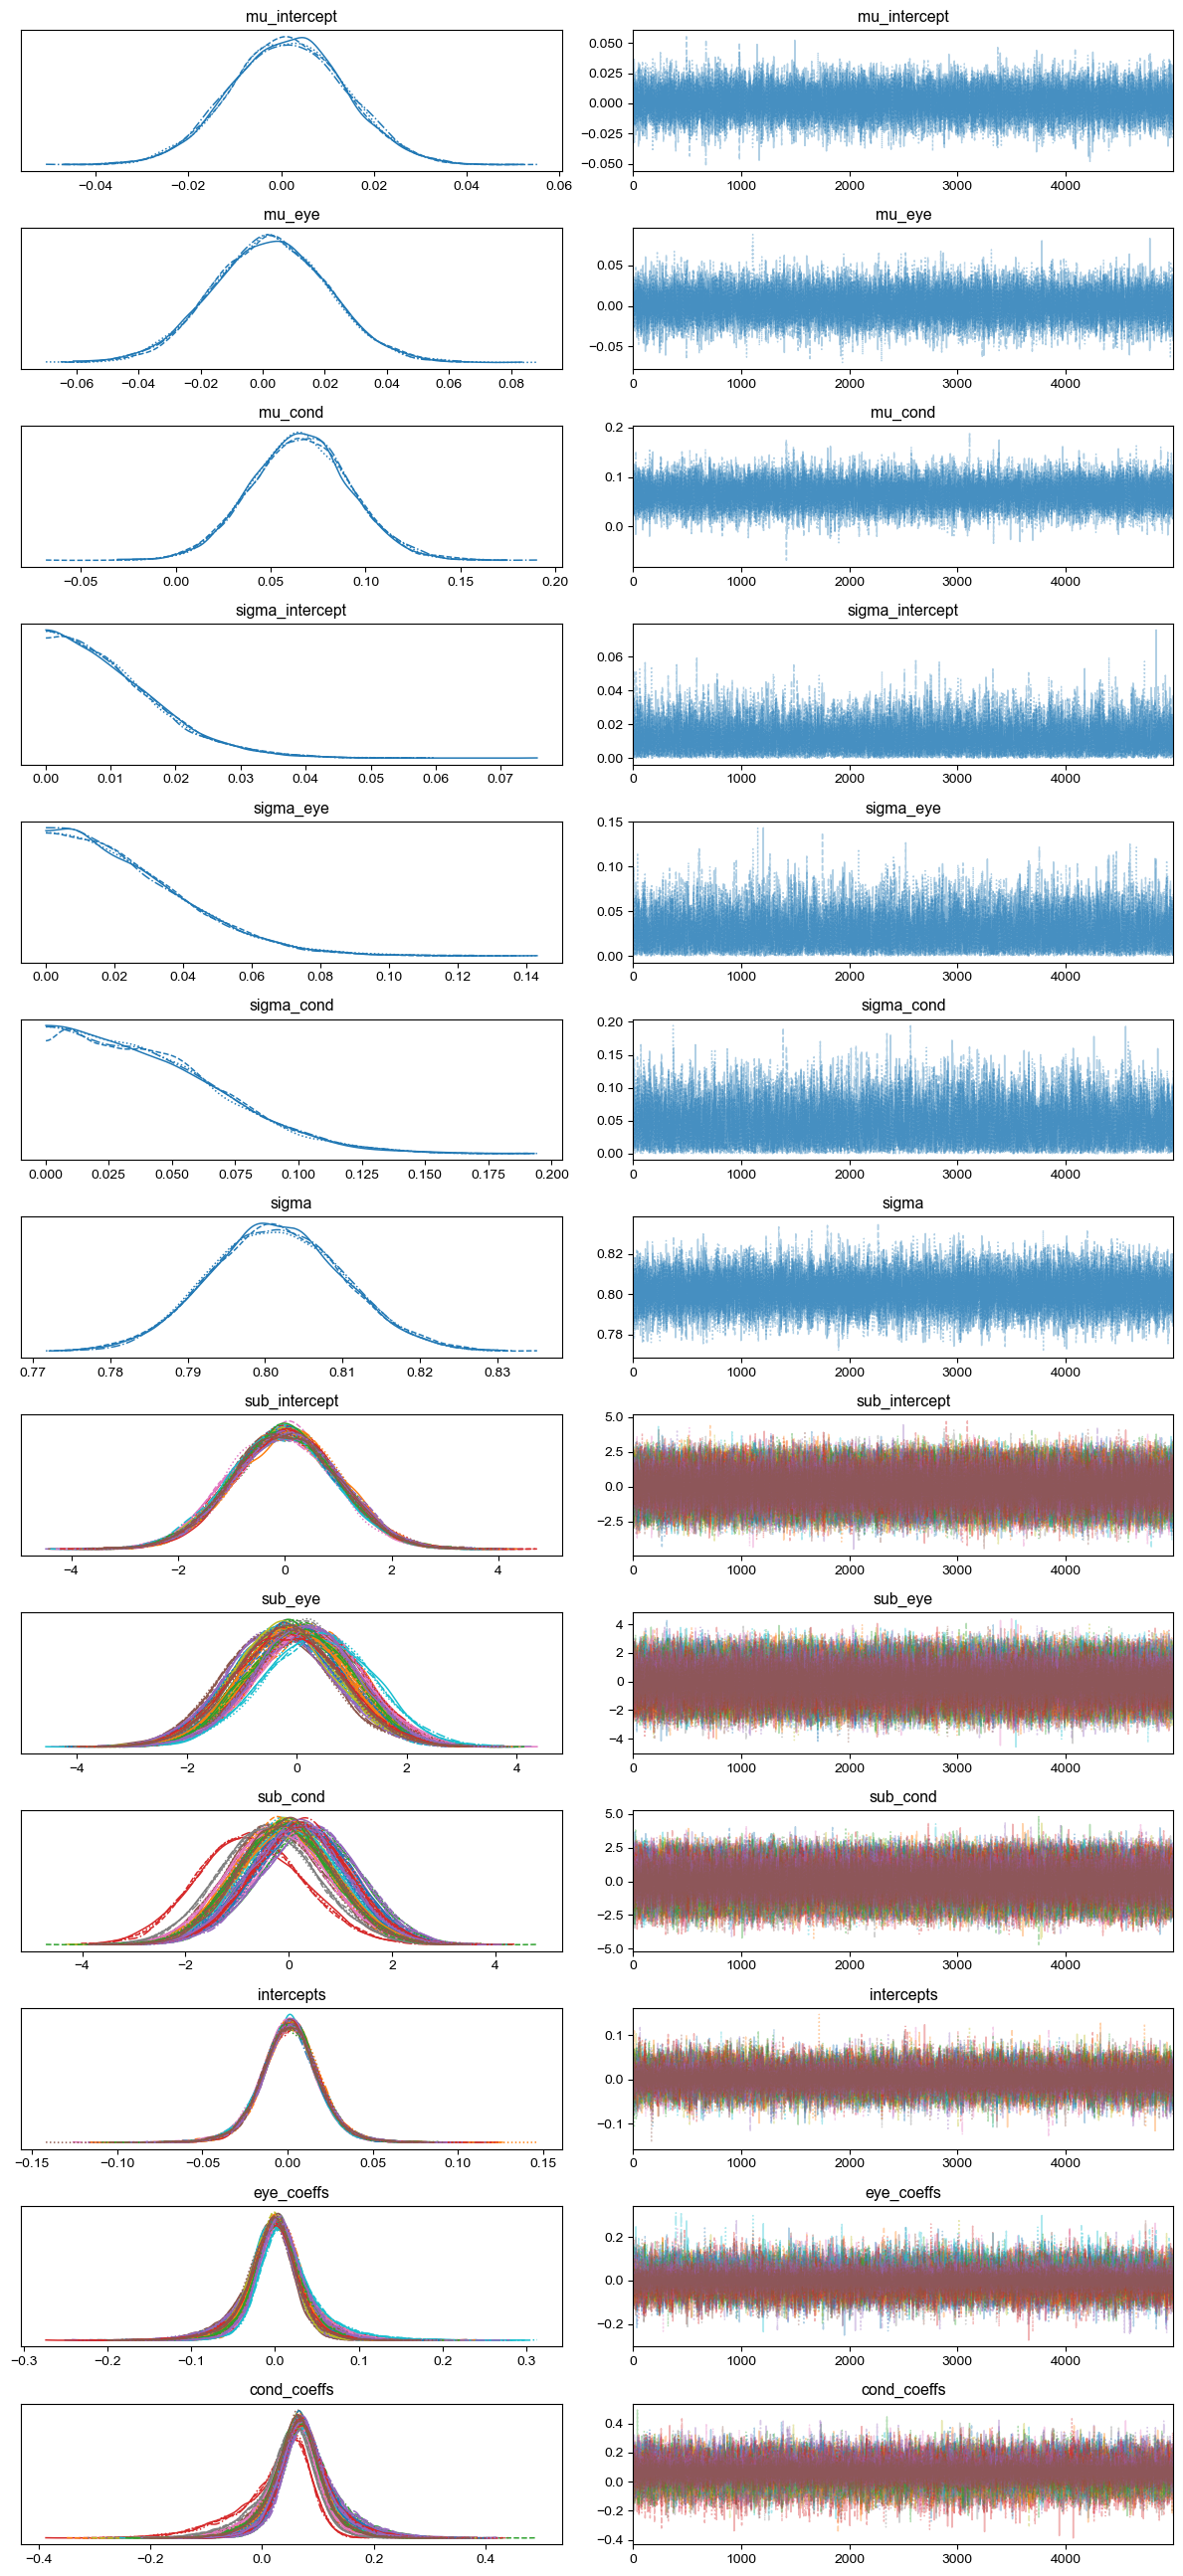

In [20]:
_ = pm.plot_trace(
    trace,
    var_names=[
        "mu_intercept",
        "mu_eye",
        "mu_cond",
        "sigma_intercept",
        "sigma_eye",
        "sigma_cond",
        "sigma",
        "sub_intercept",
        "sub_eye",
        "sub_cond",
        "intercepts",
        "eye_coeffs",
        "cond_coeffs",
    ],
)
plt.tight_layout()
plt.show()
plt.close()

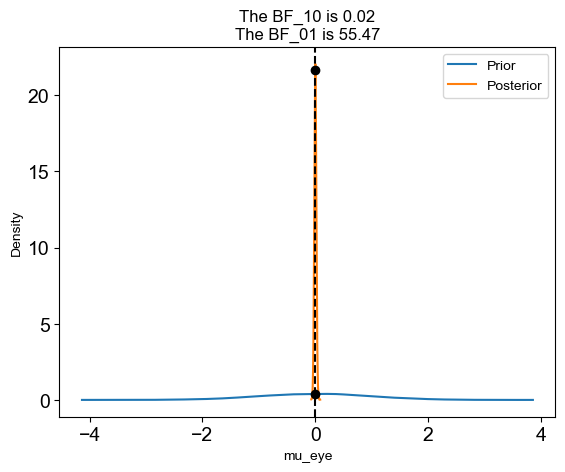

In [21]:
bf, fig = az.plot_bf(trace, var_name="mu_eye", ref_val=0)
plt.show()
plt.close()

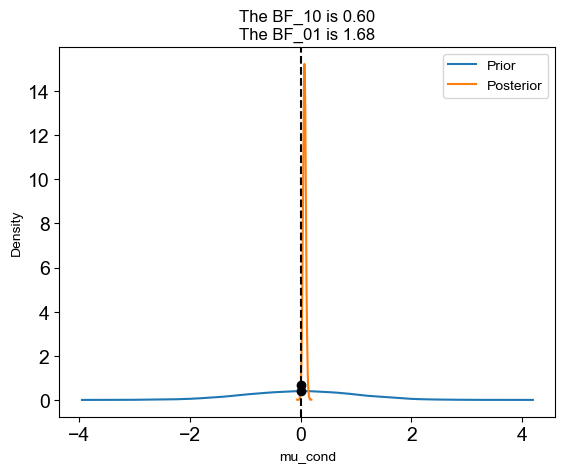

In [22]:
bf, fig = az.plot_bf(trace, var_name="mu_cond", ref_val=0)
plt.show()
plt.close()

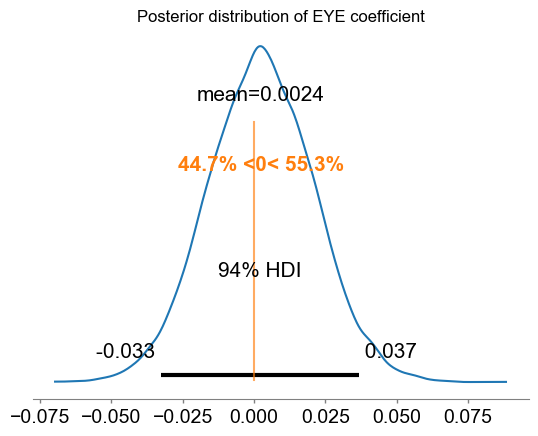

In [23]:
mu_eye_samples = trace.posterior["mu_eye"].values.flatten()
az.plot_posterior(mu_eye_samples, ref_val=0)
plt.title("Posterior distribution of EYE coefficient")
plt.show()
plt.close()

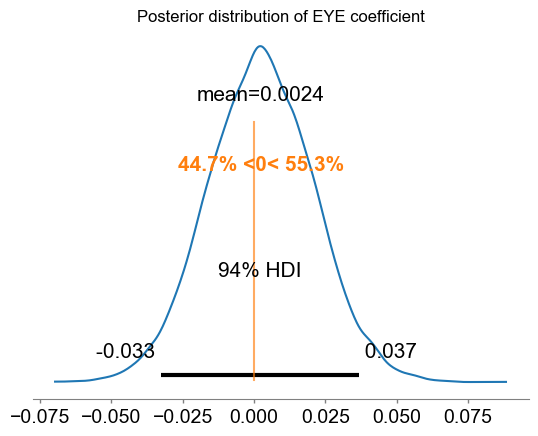

In [24]:
mu_eye_samples = trace.posterior["mu_eye"].values.flatten()
az.plot_posterior(mu_eye_samples, ref_val=0)
plt.title("Posterior distribution of EYE coefficient")
plt.show()
plt.close()

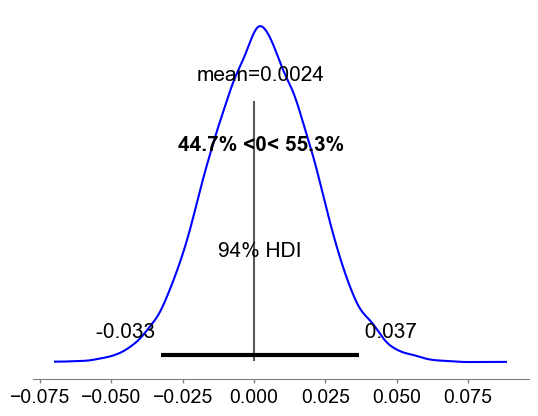

In [25]:
mu_eye_samples = trace.posterior["mu_eye"].values.flatten()
az.plot_posterior(mu_eye_samples, ref_val=0, ref_val_color="k", color="blue" if "A" in RUN_DESCRIPTION else "red")
plt.title("")
plt.savefig(f"figures/eye_param_posterior_desc-{RUN_DESCRIPTION}.png", bbox_inches="tight", transparent=True, dpi=300)
plt.show()
plt.close()

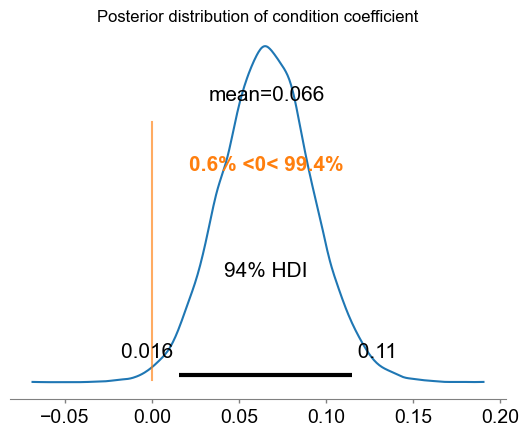

In [26]:
mu_cond_samples = trace.posterior["mu_cond"].values.flatten()
az.plot_posterior(mu_cond_samples, ref_val=0)
plt.title("Posterior distribution of condition coefficient")
plt.show()
plt.close()

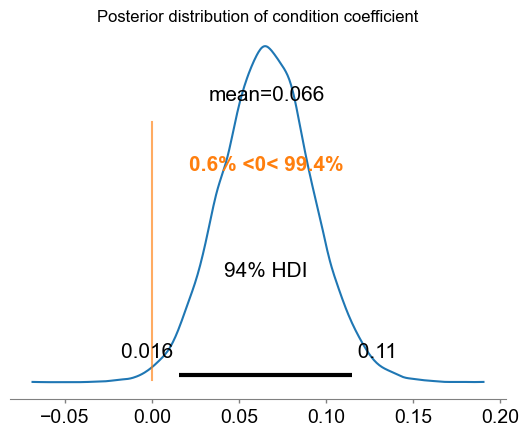

In [27]:
mu_cond_samples = trace.posterior["mu_cond"].values.flatten()
az.plot_posterior(mu_cond_samples, ref_val=0)
plt.title("Posterior distribution of condition coefficient")
plt.show()
plt.close()

# Rerun the at each timepoint

In [28]:
def pipeline(t):
    # 1. Build up dataframe of predictions at a given timepoint
    preds_df = pd.DataFrame()
    for isub in range(len(preds_perTrial)):
        sub_preds = preds_perTrial[isub]
        sub_preds_EYES = preds_EYES_perTrial[isub]
        sub_conds = conds[isub]
        cond_mask = np.isin(sub_conds, train_codes)
        # subset to training conditions only, since we're only interested in MI between conditions making up the contrast, for now,
        # average across iterations, and then across the delay period
        sub_preds = sub_preds[cond_mask][:, t]
        sub_preds_EYES = sub_preds_EYES[cond_mask][:, t]
        sub_conds = sub_conds[cond_mask]

        sub_df = pd.DataFrame({"EEG": sub_preds, "EYE": sub_preds_EYES, "cond": rescale_conds(sub_conds)})
        sub_df["sub"] = isub
        preds_df = pd.concat([preds_df, sub_df], ignore_index=True)

    preds_df["cond"] -= 0.5  # rescale conditions to be between -0.5 and 0.5, for better interpretability in modeling

    # 2. Build the model
    model = build_model(preds_df, eye_col="EYE")

    # 3. Sample from the posterior (& prior predictive)
    with model:
        trace = pm.sample(
            5000,  # real samples per chain
            tune=4000,  # warmup samples per chain
            chains=4,
            random_seed=0,
            target_accept=0.95,
            return_inferencedata=True,
            idata_kwargs={"log_likelihood": True},
            nuts_sampler="numpyro",
        )
        trace.extend(pm.sample_prior_predictive(20_000))  # add prior predictive samples to the idata for later checks

    # 4. Confirm convergence and summarize results
    summary_table = az.summary(trace)

    # 5. get the bayes factors
    cond_bf, _ = az.plot_bf(trace, var_name="mu_cond", ref_val=0)
    plt.close()

    eye_bf, _ = az.plot_bf(trace, var_name="mu_eye", ref_val=0)
    plt.close()

    return summary_table, cond_bf, eye_bf


In [29]:
if OVERWRITE or not path.exists(f"model_comparison_eyes/summary_table_desc-{RUN_DESCRIPTION}_t-0_model-EYES.csv"):
    summary_tables = []
    cond_bfs = []
    eye_bfs = []
    for t in tqdm(range(len(times))):
        summary_table, cond_bf, eye_bf = pipeline(t)
        summary_tables.append(summary_table)
        cond_bfs.append(cond_bf)
        eye_bfs.append(eye_bf)

    # save the summary tables and bayes factors for later analysis
    for t, summary_table in enumerate(summary_tables):
        summary_table.to_csv(f"model_comparison_eyes/summary_table_desc-{RUN_DESCRIPTION}_t-{t}_model-EYES.csv")

    with open(f"model_comparison_eyes/bayes_factors_desc-{RUN_DESCRIPTION}_factor-condition_model-EYES.json", "w") as f:
        json.dump(cond_bfs, f)

    with open(f"model_comparison_eyes/bayes_factors_desc-{RUN_DESCRIPTION}_factor-eye_model-EYES.json", "w") as f:
        json.dump(eye_bfs, f)
else:
    # load the summary tables and bayes factors for later analysis
    summary_tables = []
    cond_bfs = []
    eye_bfs = []
    for t in tqdm(range(len(times))):
        summary_table = pd.read_csv(f"model_comparison_eyes/summary_table_desc-{RUN_DESCRIPTION}_t-{t}_model-EYES.csv", index_col=0)
        summary_tables.append(summary_table)

    with open(f"model_comparison_eyes/bayes_factors_desc-{RUN_DESCRIPTION}_factor-condition_model-EYES.json", "r") as f:
        cond_bfs = json.load(f)

    with open(f"model_comparison_eyes/bayes_factors_desc-{RUN_DESCRIPTION}_factor-eye_model-EYES.json", "r") as f:
        eye_bfs = json.load(f)

  0%|          | 0/55 [00:00<?, ?it/s]

In [30]:
min_ess = min([summary_table.loc[["mu_eye", "mu_cond"]].ess_bulk.min() for summary_table in summary_tables]) # for interpreted parameters
max_rhat = max([summary_table.r_hat.max() for summary_table in summary_tables])
min_ess, max_rhat

(7675.0, 1.0)

In [31]:
cond_bfs_across_time = np.array([bfd["BF10"] for bfd in cond_bfs])
eye_bfs_across_time = np.array([bfd["BF10"] for bfd in eye_bfs])
bf_df = pd.DataFrame({"time": times, "cond_bf": cond_bfs_across_time, "eye_bf": eye_bfs_across_time})
bf_df["Log(BF10) Condition"] = np.log10(bf_df["cond_bf"])
bf_df["Log(BF10) Eye Scores"] = np.log10(bf_df["eye_bf"])

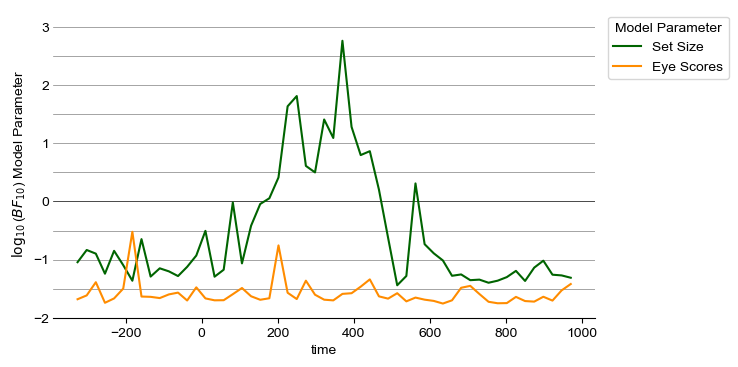

In [32]:
plt.figure(figsize=(7, 4))
sns.lineplot(data=bf_df, x="time", y="Log(BF10) Condition", label="Set Size", color="darkgreen")
ax = sns.lineplot(data=bf_df, x="time", y="Log(BF10) Eye Scores", label="Eye Scores", color="darkorange")
# add grid lines at Log10(1/10), Log10(1/5), Log10(1/3), Log10(1), Log10(3), Log10(5), Log10(10)

for i in range(6, -4, -1):
    if i == 0:
        plt.axhline(i, color="k", linestyle="-", linewidth=0.5, zorder=-1)
    else:
        plt.axhline(i/2, color="gray", linestyle="-", linewidth=0.5, zorder=-1)

plt.legend(title="Model Parameter", bbox_to_anchor=(1.01, 1), loc="upper left")
sns.despine()
plt.gca().spines["left"].set_visible(False)
plt.gca().yaxis.set_ticks_position("none")
plt.gca().yaxis.set_tick_params(pad=-1)
plt.ylim(-2, 3.3)
plt.yticks([-2, -1, 0, 1, 2, 3])
_ = plt.ylabel(r"$\log_{10}$($BF_{10}$) Model Parameter")
plt.savefig(f"figures/bayes_factors_desc-{RUN_DESCRIPTION}_model-EYES.png", bbox_inches="tight", transparent=True, dpi=300)
plt.show()
plt.close()

# Repeat everything now using the classifier scores based on pupils!

In [33]:
interp = mvEEG.Interpreter(
    data_dir=ROOT,
    experiment_name=EXPERIMENT_NAME,
    descriptions=[RUN_DESCRIPTION],
    labels=[0, 1],
    trial_phases={"Stim": (0, 200)},
    key_set=["predsPerTrialPUPIL"]
)

preds_PUPIL_perTrial = interp.dataset.get_data(
    None, keys=["predsPerTrialPUPIL"]
)

del interp  # free up memory, since we don't need it anymore

/Users/henryjones/Documents/research/banyan/Experiment 1/analyses/mvEEG/mvEEG/dataloader.py:101: UserWarning: Data files have inconsistent shapes: [[1000 1131   55]
 [1000 1184   55]
 [1000 1189   55]
 [1000 1253   55]
 [1000 1260   55]
 [1000 1286   55]
 [1000 1291   55]
 [1000 1313   55]
 [1000 1315   55]
 [1000 1319   55]
 [1000 1323   55]
 [1000 1334   55]
 [1000 1341   55]
 [1000 1358   55]
 [1000 1359   55]
 [1000 1360   55]
 [1000 1362   55]
 [1000 1367   55]
 [1000 1382   55]
 [1000 1388   55]
 [1000 1394   55]
 [1000 1401   55]
 [1000 1402   55]
 [1000 1409   55]
 [1000 1431   55]
 [1000 1436   55]]
  warnings.warn(f"Data files have inconsistent shapes: {shape}")


In [34]:
# mean across iterations
preds_PUPIL_perTrial_meaned = [p.mean(0) for p in preds_PUPIL_perTrial]
del preds_PUPIL_perTrial  # free up memory, since we don't need it anymore

preds_PUPIL_perTrial = preds_PUPIL_perTrial_meaned

In [35]:
preds_df = pd.DataFrame()
for isub in range(len(preds_perTrial)):
    sub_preds = preds_perTrial[isub]
    sub_preds_PUPIL = preds_PUPIL_perTrial[isub]
    sub_conds = conds[isub]
    cond_mask = np.isin(sub_conds, train_codes)
    # subset to training conditions only, since we're only interested in MI between conditions making up the contrast, for now,
    # average across iterations, and then across the delay period
    sub_preds = sub_preds[cond_mask][:, eeg_window].mean(1)
    sub_preds_PUPIL = sub_preds_PUPIL[cond_mask][:, pupil_window].mean(1)
    sub_conds = sub_conds[cond_mask]

    sub_df = pd.DataFrame({"EEG": sub_preds, "PUPIL": sub_preds_PUPIL, "cond": rescale_conds(sub_conds)})
    sub_df["sub"] = isub
    preds_df = pd.concat([preds_df, sub_df], ignore_index=True)

preds_df["cond"] -= 0.5  # rescale conditions to be between -0.5 and 0.5, for better interpretability in modeling

In [36]:
model = build_model(preds_df, eye_col="PUPIL")

In [37]:
with model:
    trace = pm.sample(
        5000,  # real samples per chain
        tune=4000,  # warmup samples per chain
        chains=4,
        random_seed=0,
        target_accept=0.95,
        return_inferencedata=True,
        idata_kwargs={"log_likelihood": True},
        nuts_sampler="numpyro",
    )
    trace.extend(pm.sample_prior_predictive(20_000))  # add prior predictive samples to the idata for later checks

  0%|          | 0/9000 [00:00<?, ?it/s]

  0%|          | 0/9000 [00:00<?, ?it/s]

  0%|          | 0/9000 [00:00<?, ?it/s]

  0%|          | 0/9000 [00:00<?, ?it/s]

Sampling: [EEG_obs, mu_cond, mu_eye, mu_intercept, sigma, sigma_cond, sigma_eye, sigma_intercept, sub_cond, sub_eye, sub_intercept]


In [38]:
summary_table = az.summary(trace)
summary_table

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
mu_intercept,0.002,0.012,-0.021,0.025,0.000,0.000,37237.0,15338.0,1.0
mu_eye,-0.009,0.018,-0.042,0.026,0.000,0.000,30603.0,16307.0,1.0
mu_cond,0.066,0.026,0.016,0.115,0.000,0.000,33508.0,15190.0,1.0
sub_intercept[0],-0.002,0.964,-1.856,1.771,0.005,0.008,45456.0,15101.0,1.0
sub_intercept[1],0.001,0.980,-1.823,1.846,0.005,0.008,44363.0,14270.0,1.0
...,...,...,...,...,...,...,...,...,...
cond_coeffs[21],0.064,0.050,-0.036,0.159,0.000,0.000,31649.0,16509.0,1.0
cond_coeffs[22],0.061,0.050,-0.034,0.164,0.000,0.000,33320.0,16411.0,1.0
cond_coeffs[23],0.079,0.051,-0.016,0.180,0.000,0.000,27336.0,16179.0,1.0
cond_coeffs[24],0.075,0.050,-0.021,0.172,0.000,0.000,31382.0,16632.0,1.0


In [39]:
summary_table.loc[["mu_eye", "mu_cond"]]

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
mu_eye,-0.009,0.018,-0.042,0.026,0.0,0.0,30603.0,16307.0,1.0
mu_cond,0.066,0.026,0.016,0.115,0.0,0.0,33508.0,15190.0,1.0


In [40]:
summary_table.ess_bulk.describe()

count      163.000000
mean     34930.883436
std       7583.283345
min       7085.000000
25%      30860.500000
50%      34262.000000
75%      41572.500000
max      48978.000000
Name: ess_bulk, dtype: float64

In [41]:
summary_table.r_hat.describe()

count    163.0
mean       1.0
std        0.0
min        1.0
25%        1.0
50%        1.0
75%        1.0
max        1.0
Name: r_hat, dtype: float64

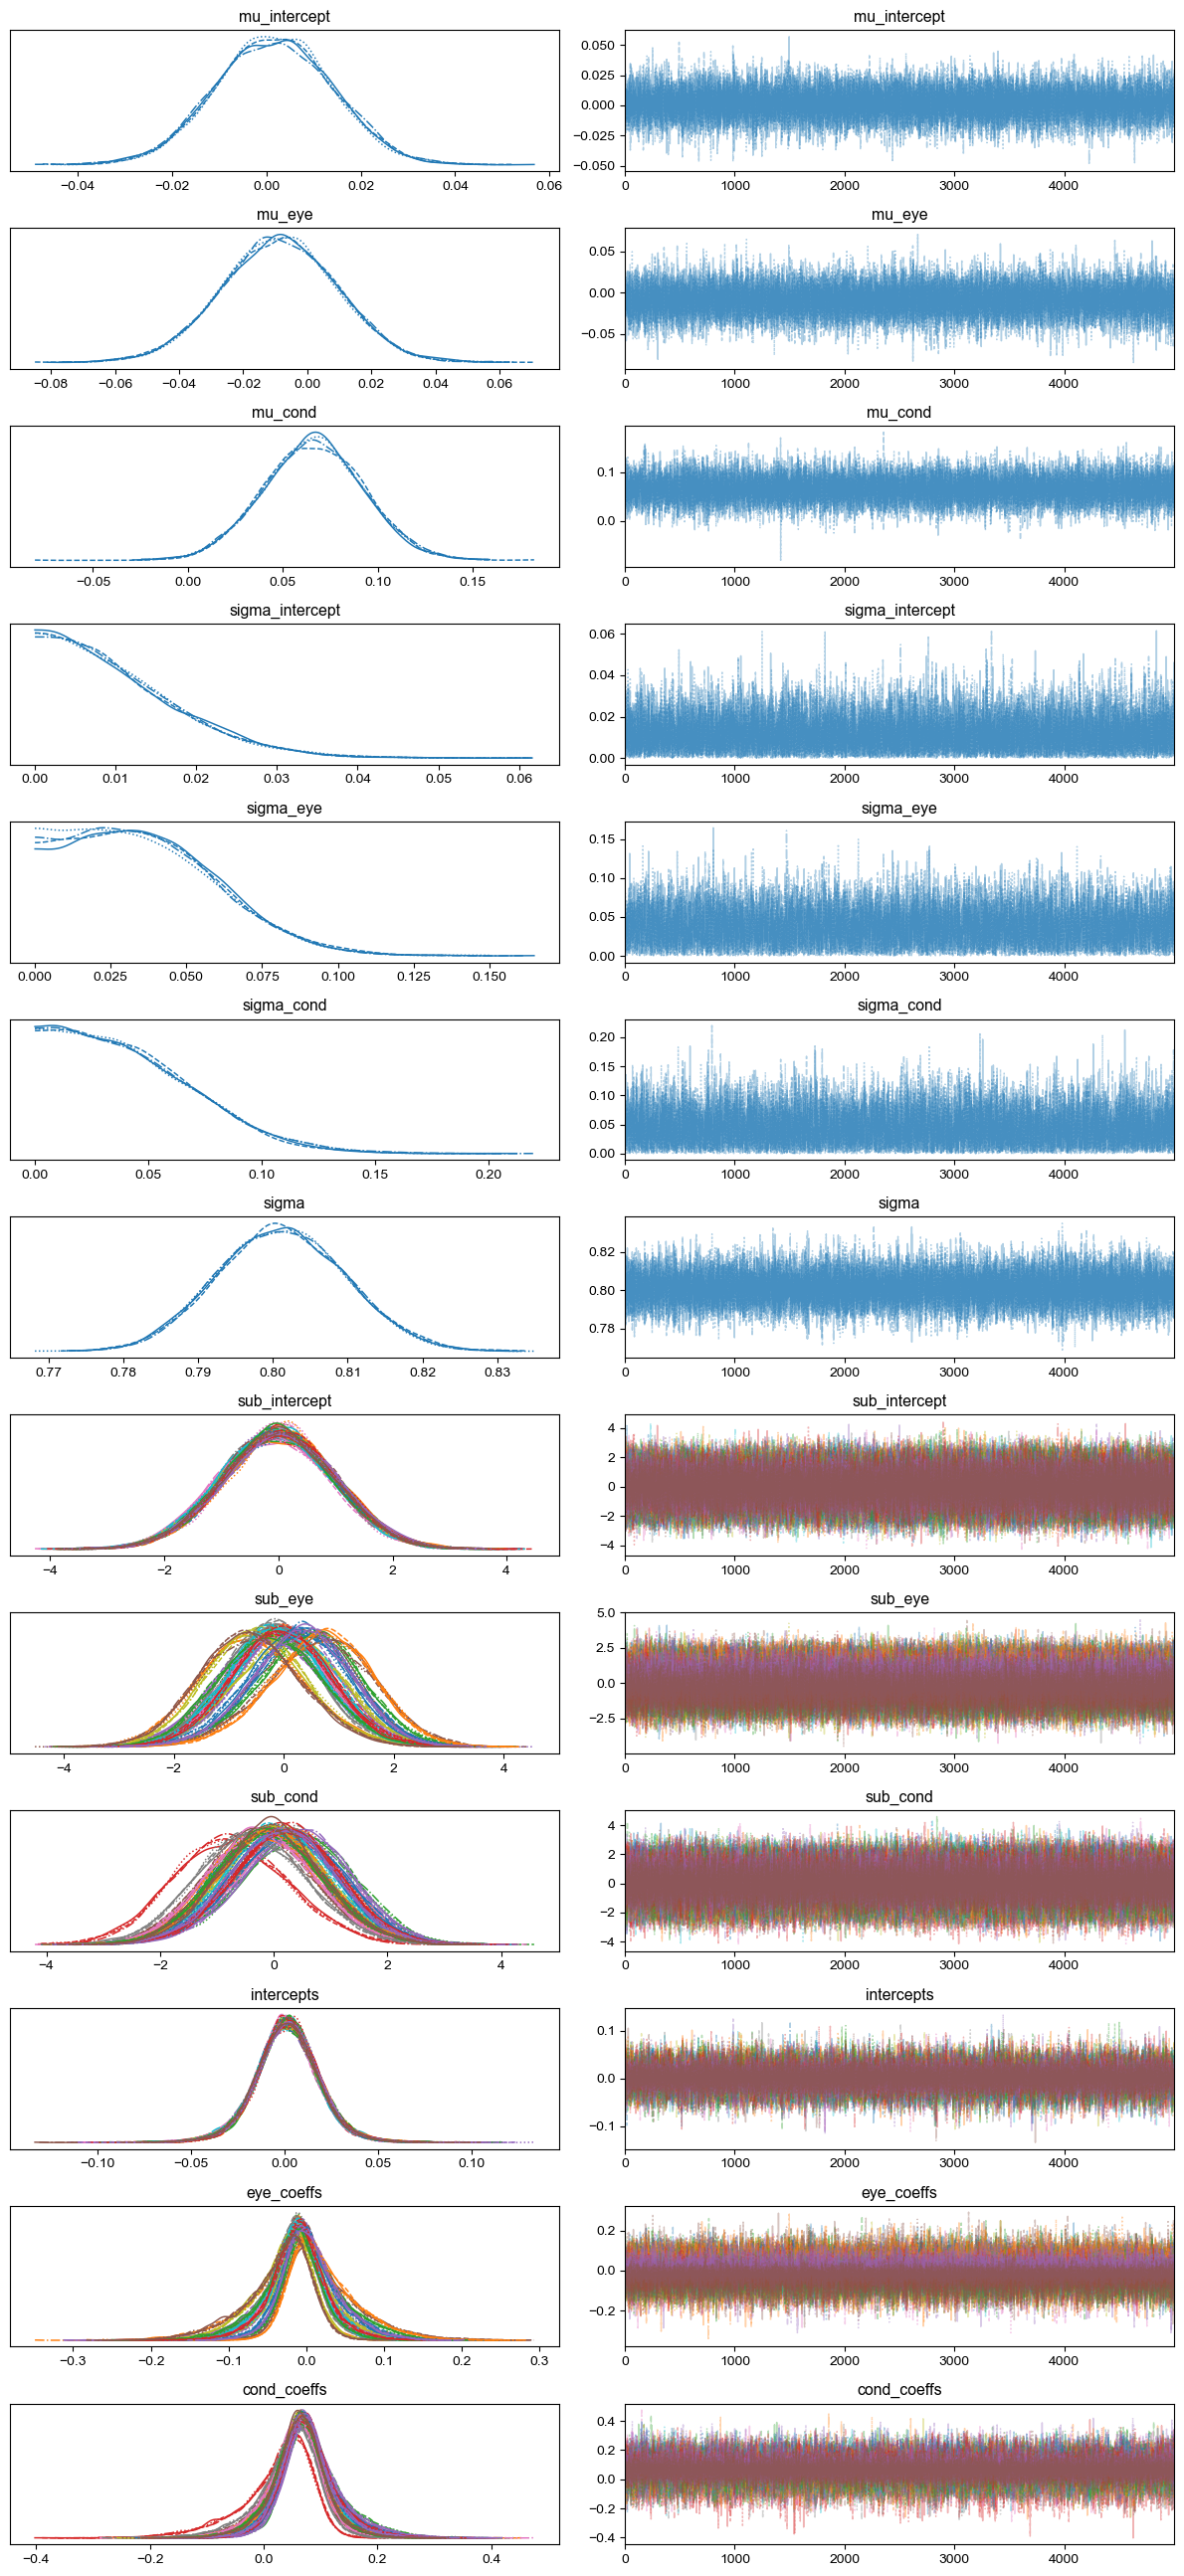

In [42]:
_ = pm.plot_trace(
    trace,
    var_names=[
        "mu_intercept",
        "mu_eye",
        "mu_cond",
        "sigma_intercept",
        "sigma_eye",
        "sigma_cond",
        "sigma",
        "sub_intercept",
        "sub_eye",
        "sub_cond",
        "intercepts",
        "eye_coeffs",
        "cond_coeffs",
    ],
)
plt.tight_layout()
plt.show()
plt.close()

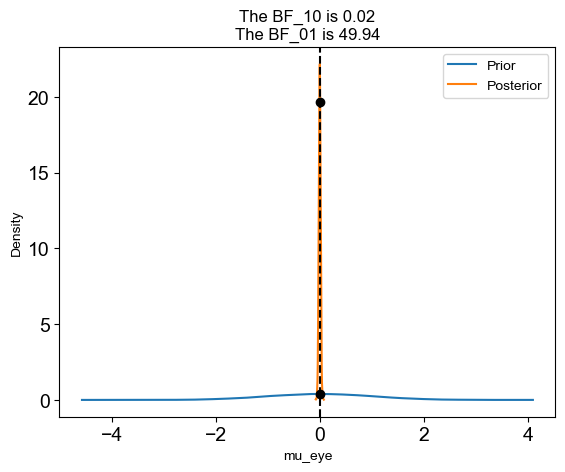

In [43]:
bf, fig = az.plot_bf(trace, var_name="mu_eye", ref_val=0)
plt.show()
plt.close()

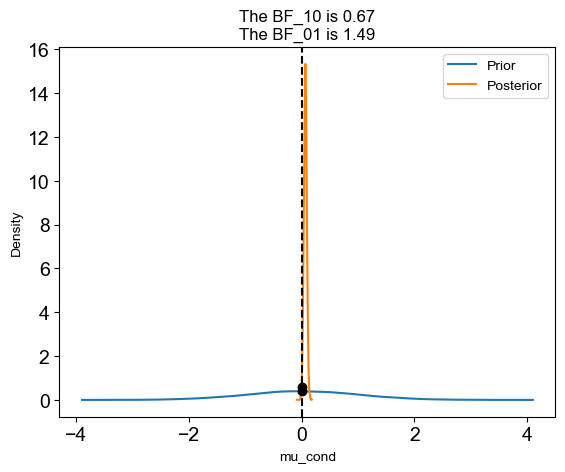

In [44]:
bf, fig = az.plot_bf(trace, var_name="mu_cond", ref_val=0)
plt.show()
plt.close()

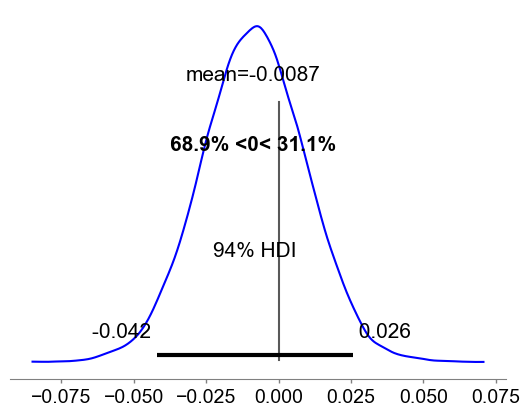

In [45]:
mu_eye_samples = trace.posterior["mu_eye"].values.flatten()
az.plot_posterior(mu_eye_samples, ref_val=0, ref_val_color="k", color="blue" if "A" in RUN_DESCRIPTION else "red")
plt.title("")
plt.show()
plt.close()

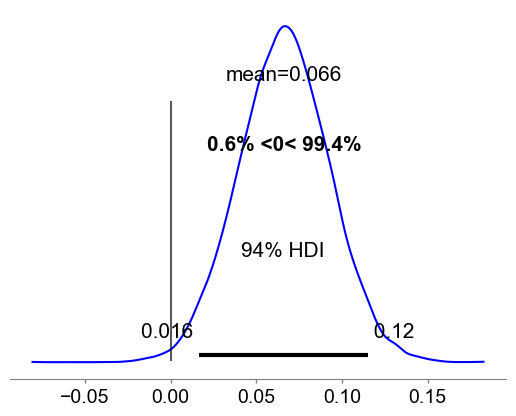

In [46]:
mu_eye_samples = trace.posterior["mu_cond"].values.flatten()
az.plot_posterior(mu_eye_samples, ref_val=0, ref_val_color="k", color="blue" if "A" in RUN_DESCRIPTION else "red")
plt.title("")
plt.show()
plt.close()

In [47]:
def pipeline_pupil(t):
    # 1. Build up dataframe of predictions at a given timepoint
    preds_df = pd.DataFrame()
    for isub in range(len(preds_perTrial)):
        sub_preds = preds_perTrial[isub]
        sub_preds_PUPIL = preds_PUPIL_perTrial[isub]
        sub_conds = conds[isub]
        cond_mask = np.isin(sub_conds, train_codes)
        # subset to training conditions only, since we're only interested in MI between conditions making up the contrast, for now,
        # average across iterations, and then across the delay period
        sub_preds = sub_preds[cond_mask][:, t]
        sub_preds_PUPIL = sub_preds_PUPIL[cond_mask][:, t]
        sub_conds = sub_conds[cond_mask]

        sub_df = pd.DataFrame({"EEG": sub_preds, "PUPIL": sub_preds_PUPIL, "cond": rescale_conds(sub_conds)})
        sub_df["sub"] = isub
        preds_df = pd.concat([preds_df, sub_df], ignore_index=True)

    preds_df["cond"] -= 0.5  # rescale conditions to be between -0.5 and 0.5, for better interpretability in modeling

    # 2. Build the model
    model = build_model(preds_df, eye_col="PUPIL")

    # 3. Sample from the posterior (& prior predictive)
    with model:
        trace = pm.sample(
            5000,  # real samples per chain
            tune=4000,  # warmup samples per chain
            chains=4,
            random_seed=0,
            target_accept=0.95,
            return_inferencedata=True,
            idata_kwargs={"log_likelihood": True},
            nuts_sampler="numpyro",
        )
        trace.extend(pm.sample_prior_predictive(20_000))  # add prior predictive samples to the idata for later checks

    # 4. Confirm convergence and summarize results
    summary_table = az.summary(trace)

    # 5. get the bayes factors
    cond_bf, _ = az.plot_bf(trace, var_name="mu_cond", ref_val=0)
    plt.close()

    eye_bf, _ = az.plot_bf(trace, var_name="mu_eye", ref_val=0)
    plt.close()

    return summary_table, cond_bf, eye_bf


In [48]:
if OVERWRITE or not path.exists(f"model_comparison_eyes/summary_table_desc-{RUN_DESCRIPTION}_t-0_model-pupil.csv"):
    summary_tables = []
    cond_bfs = []
    eye_bfs = []
    for t in tqdm(range(len(times))):
        summary_table, cond_bf, eye_bf = pipeline_pupil(t)
        summary_tables.append(summary_table)
        cond_bfs.append(cond_bf)
        eye_bfs.append(eye_bf)

    # save the summary tables and bayes factors for later analysis
    for t, summary_table in enumerate(summary_tables):
        summary_table.to_csv(f"model_comparison_eyes/summary_table_desc-{RUN_DESCRIPTION}_t-{t}_model-pupil.csv")

    with open(f"model_comparison_eyes/bayes_factors_desc-{RUN_DESCRIPTION}_factor-condition_model-pupil.json", "w") as f:
        json.dump(cond_bfs, f)

    with open(f"model_comparison_eyes/bayes_factors_desc-{RUN_DESCRIPTION}_factor-eye_model-pupil.json", "w") as f:
        json.dump(eye_bfs, f)
else:
    # load the summary tables and bayes factors for later analysis
    summary_tables = []
    cond_bfs = []
    eye_bfs = []
    for t in tqdm(range(len(times))):
        summary_table = pd.read_csv(f"model_comparison_eyes/summary_table_desc-{RUN_DESCRIPTION}_t-{t}_model-pupil.csv", index_col=0)
        summary_tables.append(summary_table)

    with open(f"model_comparison_eyes/bayes_factors_desc-{RUN_DESCRIPTION}_factor-condition_model-pupil.json", "r") as f:
        cond_bfs = json.load(f)

    with open(f"model_comparison_eyes/bayes_factors_desc-{RUN_DESCRIPTION}_factor-eye_model-pupil.json", "r") as f:
        eye_bfs = json.load(f)

  0%|          | 0/55 [00:00<?, ?it/s]

In [49]:
min_ess = min([summary_table.loc[["mu_eye", "mu_cond"]].ess_bulk.min() for summary_table in summary_tables])
max_rhat = max([summary_table.r_hat.max() for summary_table in summary_tables])
min_ess, max_rhat

(9337.0, 1.0)

In [50]:
cond_bfs_across_time = np.array([bfd["BF10"] for bfd in cond_bfs])
eye_bfs_across_time = np.array([bfd["BF10"] for bfd in eye_bfs])
bf_df = pd.DataFrame({"time": times, "cond_bf": cond_bfs_across_time, "eye_bf": eye_bfs_across_time})
bf_df["Log(BF10) Condition"] = np.log10(bf_df["cond_bf"])
bf_df["Log(BF10) Eye Scores"] = np.log10(bf_df["eye_bf"])

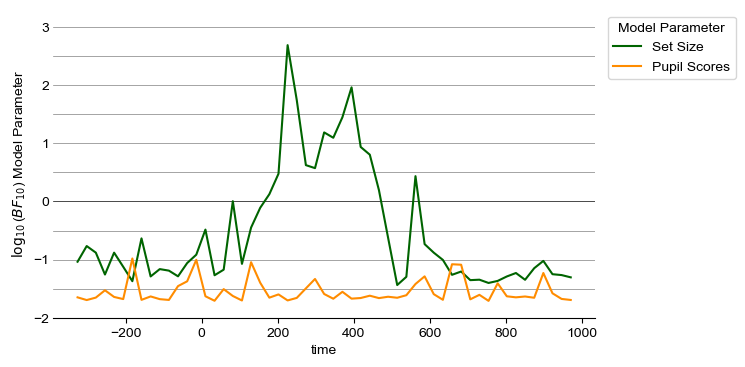

In [51]:
plt.figure(figsize=(7, 4))
sns.lineplot(data=bf_df, x="time", y="Log(BF10) Condition", label="Set Size", color="darkgreen")
ax = sns.lineplot(data=bf_df, x="time", y="Log(BF10) Eye Scores", label="Pupil Scores", color="darkorange")
for i in range(6, -4, -1):
    if i == 0:
        plt.axhline(i, color="k", linestyle="-", linewidth=0.5, zorder=-1)
    else:
        plt.axhline(i/2, color="gray", linestyle="-", linewidth=0.5, zorder=-1)

plt.legend(title="Model Parameter", bbox_to_anchor=(1.01, 1), loc="upper left")
sns.despine()
plt.gca().spines["left"].set_visible(False)
plt.gca().yaxis.set_ticks_position("none")
plt.gca().yaxis.set_tick_params(pad=-1)
plt.ylim(-2, 3.3)
plt.yticks([-2, -1, 0, 1, 2, 3])
_ = plt.ylabel(r"$\log_{10}$($BF_{10}$) Model Parameter")
plt.savefig(f"figures/bayes_factors_desc-{RUN_DESCRIPTION}_model-Pupil.png", bbox_inches="tight", transparent=True, dpi=300)
plt.show()
plt.close()